In [22]:
import pandas as pd
import numpy as np
import os

class F1DataLoader:
    def __init__(self, data_path="."):
        self.data_path = data_path
        self.races = None
        self.results = None
        self.drivers = None
        self.constructors = None
        self.tracks = None

    def load_raw_data(self):
        files = {
            "races": "Race_Schedule.csv",
            "results": "Race_Results.csv",
            "drivers": "Driver_Details.csv",
            "constructors": "Team_Details.csv",
            "tracks": "Track_Information.csv"
        }

        for attr, filename in files.items():
            try:
                path = os.path.join(self.data_path, filename)
                if os.path.exists(path):
                    setattr(self, attr, pd.read_csv(path))
                    print(f"{filename} yüklendi.")
                else:
                    print(f"UYARI: {filename} bulunamadı! Bu dosya olmadan devam edilecek.")
            except Exception as e:
                print(f"HATA: {filename} okunurken sorun çıktı: {e}")

    def _clean_columns(self):
        for df in [self.races, self.results, self.drivers, self.constructors, self.tracks]:
            if df is not None:
                df.columns = df.columns.str.lower().str.strip()

    def _safe_merge_cols(self, df, required_cols):
        available_cols = [col for col in required_cols if col in df.columns]
        missing_cols = set(required_cols) - set(available_cols)
        if missing_cols:
            print(f"Şu sütunlar {missing_cols} eksik olduğu için dahil edilmedi.")
        return df[available_cols]

    def merge_data(self):
        self._clean_columns()

        if self.results is None or self.races is None:
            raise ValueError("Race_Results veya Race_Schedule eksik, birleştirme yapılamaz!")

        # Driver isimlerinin düzenlenmesi
        if self.drivers is not None:
            if 'forename' in self.drivers.columns and 'surname' in self.drivers.columns:
                self.drivers['driver_name'] = self.drivers['forename'].astype(str) + " " + self.drivers['surname'].astype(str)
            elif 'name' in self.drivers.columns:
                self.drivers['driver_name'] = self.drivers['name']

        # Takım isimlerinin düzenlenmesi
        if self.constructors is not None and 'name' in self.constructors.columns:
            self.constructors = self.constructors.rename(columns={'name': 'team_name'})

        # Pist isimlerinin düzenlenmesi
        if self.tracks is not None and 'name' in self.tracks.columns:
            self.tracks = self.tracks.rename(columns={'name': 'circuit_name'})

        # Yarışlar ve sonuclar
        races_cols = self._safe_merge_cols(self.races, ['raceid', 'year', 'date', 'round', 'circuitid'])
        full_df = self.results.merge(races_cols, on='raceid', how='left')

        # Pilotların eklenmesi
        if self.drivers is not None:
            driver_target_cols = ['driverid', 'driver_name', 'nationality', 'date_of_birth', 'dob']
            drivers_subset = self._safe_merge_cols(self.drivers, driver_target_cols)
            full_df = full_df.merge(drivers_subset, on='driverid', how='left')

        # Takımların eklenmesi
        if self.constructors is not None:
            team_id_col = 'teamid' if 'teamid' in self.constructors.columns else 'constructorid'
            if team_id_col in self.constructors.columns:
                team_cols = [team_id_col, 'team_name', 'nationality']
                team_subset = self._safe_merge_cols(self.constructors, team_cols)
                full_df = full_df.merge(team_subset, left_on='constructorid', right_on=team_id_col, how='left', suffixes=('_driver', '_team'))

        # Pistlerin eklenmesi
        if self.tracks is not None:
            track_cols = ['circuitid', 'circuit_name', 'country', 'lat', 'lng', 'alt']
            track_subset = self._safe_merge_cols(self.tracks, track_cols)
            if 'circuitid' in full_df.columns:
                full_df = full_df.merge(track_subset, on='circuitid', how='left')

        # Tarih ve Sıralama
        if 'date' in full_df.columns:
            full_df['date'] = pd.to_datetime(full_df['date'], errors='coerce')
            full_df = full_df.sort_values(by=['date', 'position'])

        print(f"Satır sayısı: {len(full_df)}")
        print("Sütunlar:", full_df.columns.tolist())

        return full_df

loader = F1DataLoader()
loader.load_raw_data()
df = loader.merge_data()
df.head()

Race_Schedule.csv yüklendi.
Race_Results.csv yüklendi.
Driver_Details.csv yüklendi.
Team_Details.csv yüklendi.
Track_Information.csv yüklendi.
Şu sütunlar {'date_of_birth'} eksik olduğu için dahil edilmedi.
Satır sayısı: 26519
Sütunlar: ['resultid', 'raceid', 'driverid', 'constructorid', 'number', 'grid', 'position', 'positiontext', 'positionorder', 'points', 'laps', 'time', 'milliseconds', 'fastestlap', 'rank', 'fastestlaptime', 'fastestlapspeed', 'statusid', 'year', 'date', 'round', 'circuitid', 'driver_name', 'nationality_driver', 'dob', 'team_name', 'nationality_team', 'circuit_name', 'country', 'lat', 'lng', 'alt']


,resultid,raceid,driverid,constructorid,number,grid,position,positiontext,positionorder,points,...,driver_name,nationality_driver,dob,team_name,nationality_team,circuit_name,country,lat,lng,alt
20024,20025,833,642,51,2,1,1,1,1,9.0,...,Nino Farina,Italian,1906-10-30,Alfa Romeo,Swiss,Silverstone Circuit,UK,52.0786,-1.01694,153
20033,20034,833,778,105,10,20,10,10,10,0.0,...,Brian Shawe Taylor,British,1915-01-28,Maserati,Italian,Silverstone Circuit,UK,52.0786,-1.01694,153
20176,20177,833,788,105,10,20,10,10,10,0.0,...,Joe Fry,British,1915-10-26,Maserati,Italian,Silverstone Circuit,UK,52.0786,-1.01694,153
20034,20035,833,660,154,18,21,11,11,11,0.0,...,Johnny Claes,Belgian,1916-08-11,Talbot-Lago,French,Silverstone Circuit,UK,52.0786,-1.01694,153
20025,20026,833,786,51,3,2,2,2,2,6.0,...,Luigi Fagioli,Italian,1898-06-09,Alfa Romeo,Swiss,Silverstone Circuit,UK,52.0786,-1.01694,153


In [23]:
import pandas as pd
import numpy as np

class F1FeatureEngineer:
    def __init__(self, df):
        self.df = df.copy()

    def process(self):
        # Veri Hazırlığı
        # 'position' sütunundaki "R" (Retired), "D" (Disqualified) gibi harfleri NaN yapalım
        # Böylece sayısal işlemler hata vermez.
        self.df['position'] = pd.to_numeric(self.df['position'], errors='coerce')

        # Kronolojik sıralama
        self.df = self.df.sort_values(by=['year', 'round', 'position'])

        # Sezonluk Puan
        print("   -> Sezonluk puanlar hesaplanıyor...")
        self.df['current_season_points'] = (
            self.df.groupby(['year', 'driverid'])['points']
            .cumsum()
            - self.df['points']
        )

        # Son 5 Yarış Formu
        self.df['driver_recent_form'] = (
            self.df.groupby(['year', 'driverid'])['points']
            .transform(lambda x: x.shift(1).rolling(window=5, min_periods=1).mean())
            .fillna(0)
        )

        # Takım Formu

        self.df['team_recent_form'] = (
            self.df.groupby(['year', 'constructorid'])['points']
            .transform(lambda x: x.shift(1).rolling(window=5, min_periods=1).mean())
            .fillna(0)
        )

        # Pist Uzmanlığı
        self.df['driver_track_history'] = (
            self.df.groupby(['driverid', 'circuitid'])['points']
            .transform(lambda x: x.shift(1).expanding().mean())
            .fillna(0)
        )

        # Kazanma Oranı
        self.df['is_win'] = (self.df['position'] == 1).astype(int)
        self.df['driver_win_ratio'] = (
            self.df.groupby('driverid')['is_win']
            .transform(lambda x: x.shift(1).expanding().mean())
            .fillna(0)
        )
        self.df['is_dnf'] = self.df['position'].isna().astype(int)
        self.df['reliability_index'] = (
            self.df.groupby('constructorid')['is_dnf']
            .transform(lambda x: x.shift(1).rolling(window=10, min_periods=1).mean())
            .fillna(0)
        )

        # Temizlik
        drop_cols = ['is_win', 'is_dnf']
        self.df.drop(columns=[c for c in drop_cols if c in self.df.columns], inplace=True)
        self.df.fillna(0, inplace=True)
        return self.df

engineer = F1FeatureEngineer(df)
df_ready = engineer.process()

print(df_ready[['year', 'driver_name', 'reliability_index']].tail(3))


   -> Sezonluk puanlar hesaplanıyor...
       year     driver_name  reliability_index
26516  2024     Guanyu Zhou                0.0
26517  2024  George Russell                0.0
26518  2024    Pierre Gasly                0.1


Eğitim Seti: 26280 satır
Test Seti: 239 satır

Model eğitiliyor (Random Forest)...
Accuracy:  0.941
Precision: 0.444
Recall:    0.667 


/tmp/ipython-input-2262891046.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance, y=self.features, palette="viridis")


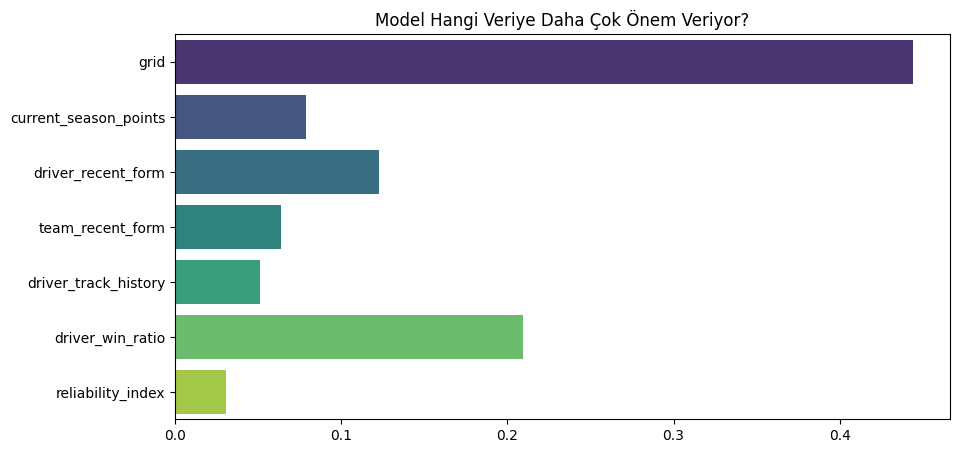


ÖRNEK TAHMİN: 2024 Round 12 (Silverstone)


,driver_name,team_name,grid,win_probability
26499,Lewis Hamilton,Mercedes,2,0.812744
26517,George Russell,Mercedes,1,0.639667
26500,Max Verstappen,Red Bull,4,0.328576
26501,Lando Norris,McLaren,3,0.255399
26502,Oscar Piastri,McLaren,5,0.121388


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

class F1ModelTrainer:
    def __init__(self, df):
        self.df = df.copy()
        self.model = None
        self.features = [
            'grid',
            'current_season_points',
            'driver_recent_form',
            'team_recent_form',
            'driver_track_history',
            'driver_win_ratio',
            'reliability_index'
        ]
        self.target = 'is_winner'

    def prepare_data(self):
        #Pozisyon 1se kazandı kazanamadıysa 0
        self.df['is_winner'] = (self.df['position'] == 1).astype(int)
        self.df['grid'] = self.df['grid'].replace(0, 20)

        train_mask = self.df['year'] < 2024
        test_mask = self.df['year'] == 2024

        X_train = self.df.loc[train_mask, self.features]
        y_train = self.df.loc[train_mask, self.target]

        X_test = self.df.loc[test_mask, self.features]
        y_test = self.df.loc[test_mask, self.target]


        test_info = self.df.loc[test_mask, ['year', 'round', 'circuit_name', 'driver_name', 'team_name', 'grid']]

        print(f"Eğitim Seti: {X_train.shape[0]} satır")
        print(f"Test Seti: {X_test.shape[0]} satır")

        return X_train, y_train, X_test, y_test, test_info

    def train(self):
        X_train, y_train, X_test, y_test, test_info = self.prepare_data()

        print("\nModel eğitiliyor (Random Forest)...")
        self.model = RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            random_state=42,
            class_weight='balanced'
        )
        self.model.fit(X_train, y_train)
        return X_test, y_test, test_info

    def evaluate(self, X_test, y_test):
        y_pred = self.model.predict(X_test)

        print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
        print(f"Precision: {precision_score(y_test, y_pred):.3f}")
        print(f"Recall:    {recall_score(y_test, y_pred):.3f} ")

        importance = self.model.feature_importances_
        plt.figure(figsize=(10, 5))
        sns.barplot(x=importance, y=self.features, palette="viridis")
        plt.title("Model Hangi Veriye Daha Çok Önem Veriyor?")
        plt.show()

    def predict_next_race(self, test_info, X_test):
        # Kazanma ihtimali
        probs = self.model.predict_proba(X_test)[:, 1]
        results = test_info.copy()
        results['win_probability'] = probs

        last_race_round = results['round'].max()
        last_race = results[results['round'] == last_race_round].sort_values(by='win_probability', ascending=False).head(5)

        print(f"\nÖRNEK TAHMİN: 2024 Round {last_race_round} (Silverstone)")
        display(last_race[['driver_name', 'team_name', 'grid', 'win_probability']])

trainer = F1ModelTrainer(df_ready)
X_test, y_test, test_info = trainer.train()
trainer.evaluate(X_test, y_test)
trainer.predict_next_race(test_info, X_test)

In [25]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, f1_score

def compare_algorithms(df):
    df_comp = df.copy()
    df_comp['is_winner'] = (df_comp['position'] == 1).astype(int)

    features = ['grid', 'current_season_points', 'driver_recent_form', 'team_recent_form',
                'driver_track_history', 'driver_win_ratio', 'reliability_index']
    target = 'is_winner'

    # Grid eksikse doldur
    df_comp['grid'] = df_comp['grid'].replace(0, 20)

    # Zaman bazlı ayrım
    train_data = df_comp[df_comp['year'] < 2024]
    test_data = df_comp[df_comp['year'] == 2024]

    X_train = train_data[features]
    y_train = train_data[target]
    X_test = test_data[features]
    y_test = test_data[target]

    # Modeller
    models = {
        "Random Forest ": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, class_weight='balanced'),
        "Gradient Boosting ": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42),
        "AdaBoost ": AdaBoostClassifier(n_estimators=100, random_state=42),
        "Logistic Regression ": make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))
    }

    results = []

    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision (Kesinlik)": precision_score(y_test, y_pred, zero_division=0),
            "F1 Score": f1_score(y_test, y_pred, zero_division=0)
        })

    results_df = pd.DataFrame(results).sort_values(by="Precision (Kesinlik)", ascending=False)
    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    return models[best_model_name]

best_model = compare_algorithms(df_ready)

,Model,Accuracy,Precision (Kesinlik),F1 Score
2,AdaBoost,0.953975,0.571429,0.421053
1,Gradient Boosting,0.953975,0.555556,0.476190
0,Random Forest,0.941423,0.444444,0.533333
3,Logistic Regression,0.803347,0.203390,0.338028


In [26]:
import pandas as pd
import numpy as np

def predict_data(model, df):

    last_year = df['year'].max()
    last_round = df[df['year'] == last_year]['round'].max()
    current_status = df[(df['year'] == last_year) & (df['round'] == last_round)].copy()

    print(f" Baz Alınan Veri: {last_year} Sezonu, {last_round}. Yarış")

    abu_dhabi_history = df[df['circuit_name'].str.contains("Yas Marina|Abu Dhabi", case=False, na=False)]

    if abu_dhabi_history.empty:
        print("Uyarı: Veri setinde geçmiş Abu Dhabi verisi bulunamadı. Genel ortalamalar kullanılacak.")

    future_race_rows = []

    for index, pilot_row in current_status.iterrows():
        driver_id = pilot_row['driverid'] if 'driverid' in pilot_row else None
        driver_name = pilot_row['driver_name']

        pilot_track_history = 0
        if not abu_dhabi_history.empty and driver_id:
            pilot_stats = abu_dhabi_history[abu_dhabi_history['driverid'] == driver_id]
            if not pilot_stats.empty:
                pilot_track_history = pilot_stats['points'].mean()
            else:
                pilot_track_history = pilot_row['driver_track_history']

        predicted_grid = pilot_row['grid']

        future_race_rows.append({
            'driver_name': driver_name,
            'team_name': pilot_row['team_name'],
            'grid': predicted_grid,
            'current_season_points': pilot_row['current_season_points'],
            'driver_recent_form': pilot_row['driver_recent_form'],
            'team_recent_form': pilot_row['team_recent_form'],
            'driver_track_history': pilot_track_history,
            'driver_win_ratio': pilot_row['driver_win_ratio'],
            'reliability_index': pilot_row['reliability_index']
        })

    # Dataframe'e çevir
    future_df = pd.DataFrame(future_race_rows)

    # TAHMİN YAP
    features = ['grid', 'current_season_points', 'driver_recent_form', 'team_recent_form',
                'driver_track_history', 'driver_win_ratio', 'reliability_index']

    probs = model.predict_proba(future_df[features])[:, 1]
    future_df['win_probability'] = probs

    # SONUCU GÖSTER
    results = future_df[['driver_name', 'team_name', 'grid', 'win_probability']].sort_values(by='win_probability', ascending=False).head(5)
    results['win_probability'] = results['win_probability'].apply(lambda x: f"%{x*100:.1f}")

    print(f"\n 2025 ABU DHABI GP TAHMİNİ:")
    display(results)

    winner = results.iloc[0]
    print(f"\n Favori: {winner['driver_name']} ({winner['team_name']})")
try:
    predict_data(best_model, trainer.df)
except NameError:
    predict_data(trainer.model, trainer.df)

 Baz Alınan Veri: 2024 Sezonu, 12. Yarış

 2025 ABU DHABI GP TAHMİNİ:


,driver_name,team_name,grid,win_probability
0,Lewis Hamilton,Mercedes,2,%48.5
18,George Russell,Mercedes,1,%45.0
1,Max Verstappen,Red Bull,4,%43.7
2,Lando Norris,McLaren,3,%36.4
3,Oscar Piastri,McLaren,5,%35.5



 Favori: Lewis Hamilton (Mercedes)
